# 03 — Model Reliability Analysis: Student Social Media Addiction Score

**Contribution:** Himel's part of the project — *experimental evaluation and model reliability analysis*.

**Question:** Can we trust the reported regression performance on the
`Addicted_Score` target? To answer it, this notebook:

1. Builds a **fair, leakage-free evaluation protocol**: fixed split, preprocessing fitted on training data only, nested cross-validation, and a test set used once.
2. Compares baseline regressors on **identical splits**: Dummy, Linear, Ridge, Random Forest and XGBoost.
3. Tests **reliability**: cross-validation vs test, overfitting, learning curves, residuals, sensitivity to the split, and bootstrap confidence intervals.
4. **Audits earlier recorded results** from the StablePFN notebook and checks the high scores for leakage.

**Relation to teammates' work (no duplication):**
- `Dataset_Plotting_Preprocessing.ipynb` already covers EDA plots and an exploratory scaling/encoding pass. This notebook does not repeat the EDA.
- The StablePFN notebook covers the custom PyTorch model and its training. This notebook does **not** retrain StablePFN. It checks the StablePFN numbers that were recorded and puts them next to properly evaluated baselines.

**Labels used throughout:**

| Label | Meaning |
|---|---|
| **VERIFIED** | Computed by running this notebook |
| **RECORDED (unverified)** | Copied from an earlier notebook's saved output, not re-run here |

> Scores predicted here are survey-scale numbers. They are **not** clinical diagnoses.
> Feature importances describe what the model relies on. They are **not** causal effects.

## 1. Setup and reproducibility

A **random seed** fixes every random choice (data shuffling, tree building), so the notebook gives the same numbers on every run.
We also save the package versions to `results/environment.json`, because different library versions can give slightly different results.

**Paths:** the notebook works if you run it from the repository root or from `notebooks/`.
The dataset is **not** committed to Git, because its redistribution permission is unclear. Put it at
`data/Students-Social-Media-Addiction-1.csv`, or point the environment variable `SMA_DATA_PATH` to it.

In [1]:
import os, json, random, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, TargetEncoder
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GridSearchCV,
                                     cross_validate, learning_curve, permutation_test_score)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    import xgboost
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:          # fall back to scikit-learn's own boosting model
    HAS_XGB = False

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# Locate the repository root whether we run from the root or from notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "results"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

candidates = [os.environ.get("SMA_DATA_PATH"),
              ROOT / "data" / "Students-Social-Media-Addiction-1.csv",
              ROOT / "Students-Social-Media-Addiction-1.csv"]
DATA_PATH = next((Path(p) for p in candidates if p and Path(p).is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Put the CSV in data/ or set SMA_DATA_PATH.")

env = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__, "matplotlib": plt.matplotlib.__version__,
       "seaborn": sns.__version__, "xgboost": xgboost.__version__ if HAS_XGB else "not installed",
       "seed": SEED}
(RESULTS / "environment.json").write_text(json.dumps(env, indent=2))
print("Data file:", DATA_PATH.name)
print(json.dumps(env, indent=2))

Data file: Students-Social-Media-Addiction-1.csv
{
  "python": "3.13.16",
  "numpy": "2.5.3",
  "pandas": "3.0.5",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.2",
  "seaborn": "0.13.2",
  "xgboost": "3.4.1",
  "seed": 42
}


## 2. Load the data and check its integrity

Before trusting any score, we check the data for problems that commonly make results look better than they are:
- **Duplicate rows.** The same student in both train and test lets the model "remember" the answer.
- **Identical inputs with different targets.** These show how much noise is in the target.
- **ID columns that carry information.** If `Student_ID` is related to the score, using it would be a leak.

In [2]:
df = pd.read_csv(DATA_PATH)
TARGET = "Addicted_Score"
assert TARGET in df.columns, "Target column missing"
FEATURES = [c for c in df.columns if c not in (TARGET, "Student_ID")]

feat_dup = df[FEATURES].duplicated(keep=False)
conflicting = (df[feat_dup].groupby(FEATURES)[TARGET].nunique() > 1).sum() if feat_dup.any() else 0
integrity = {
    "rows": len(df), "columns": df.shape[1],
    "missing_cells": int(df.isna().sum().sum()),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "duplicate_rows_ignoring_Student_ID": int(df.drop(columns="Student_ID").duplicated().sum()),
    "duplicate_feature_vectors": int(df[FEATURES].duplicated().sum()),
    "feature_duplicates_with_conflicting_target": int(conflicting),
    "Student_ID_unique": bool(df["Student_ID"].is_unique),
    "Spearman_corr_Student_ID_vs_target": round(df["Student_ID"].corr(df[TARGET], method="spearman"), 3),
    "target_min": int(df[TARGET].min()), "target_max": int(df[TARGET].max()),
    "target_mean": round(df[TARGET].mean(), 3), "target_std": round(df[TARGET].std(), 3),
}
display(pd.Series(integrity, name="value").to_frame())
print("Target value counts:")
print(df[TARGET].value_counts().sort_index().to_string())
print("\nFeatures used:", FEATURES)

,value
rows,705
columns,13
missing_cells,0
exact_duplicate_rows,0
duplicate_rows_ignoring_Student_ID,1
duplicate_feature_vectors,1
feature_duplicates_with_conflicting_target,0
Student_ID_unique,True
Spearman_corr_Student_ID_vs_target,0.032
target_min,2


Target value counts:
Addicted_Score
2      1
3     16
4     83
5    136
6     61
7    209
8    144
9     55

Features used: ['Age', 'Gender', 'Academic_Level', 'Country', 'Avg_Daily_Usage_Hours', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Mental_Health_Score', 'Relationship_Status', 'Conflicts_Over_Social_Media']


**How to read this:** The target is a whole number from 2 to 9, and the low scores 2 and 3 are rare (17 of 705 rows).
Expect any model to struggle at those extremes, because it has very few examples to learn from.

## 3. Evaluation protocol: reuse the original split and check it

The StablePFN notebook split the data like this:
`train_test_split(X, y, test_size=0.2, random_state=42)`, then took 12.5% of the remainder as validation, giving **493 / 71 / 141** rows.

We **reuse the same 141-row test set**, so our baselines are measured on exactly the rows behind the recorded StablePFN test result.
For model selection, we merge the original train and validation sets into one **development set** of 564 rows and use **cross-validation** on it.
A single 71-row validation set is too small to choose models reliably.

**Cross-validation (CV)** splits the development set into 5 parts, trains on 4 and scores on the 5th, and rotates through all 5 parts.
We repeat that 3 times with different shuffles, giving 15 scores per model, so we see an average *and* a spread.

The **test set is used once**, at the end, after every choice has been made.

Original split sizes  train/val/test: 493 71 141


,row_index,Student_ID,in_test_set
0,241,242,False
1,273,274,False


Duplicate pair straddles dev/test: False


,development (n=564),test (n=141)
Addicted_Score,,
2,0.0,0.7
3,2.5,1.4
4,12.1,10.6
5,17.9,24.8
6,9.2,6.4
7,29.8,29.1
8,20.6,19.9
9,8.0,7.1


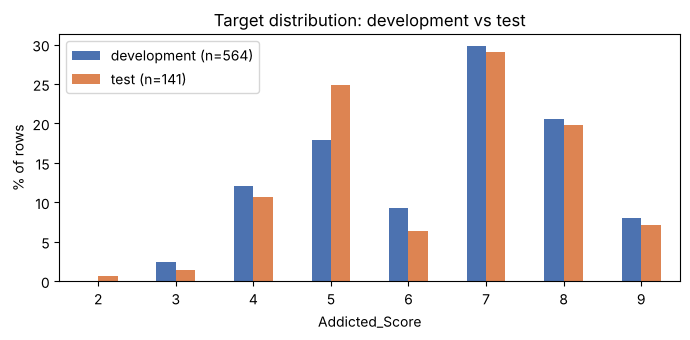

In [3]:
X = df.drop(columns=[TARGET, "Student_ID"])
y = df[TARGET]

# Exact re-creation of the original notebook's split
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_tr_orig, X_val_orig, y_tr_orig, y_val_orig = train_test_split(X_temp, y_temp, test_size=0.125, random_state=42)
print("Original split sizes  train/val/test:", len(X_tr_orig), len(X_val_orig), len(X_test))
assert (len(X_tr_orig), len(X_val_orig), len(X_test)) == (493, 71, 141), "Split does not match the original notebook"

X_dev, y_dev = X_temp, y_temp            # development set = original train + validation (564 rows)
assert set(X_dev.index).isdisjoint(X_test.index)

# Where do duplicated records (ignoring Student_ID) fall? A pair split across dev/test would leak.
dup_idx = df.index[df.drop(columns="Student_ID").duplicated(keep=False)]
dup_report = pd.DataFrame({"row_index": dup_idx, "Student_ID": df.loc[dup_idx, "Student_ID"].values,
                           "in_test_set": [i in X_test.index for i in dup_idx]})
display(dup_report)
print("Duplicate pair straddles dev/test:", dup_report.in_test_set.nunique() > 1)
pd.Series(sorted(X_test.index)).to_csv(RESULTS / "test_indices.csv", index=False, header=["row_index"])

# Is the split representative? Compare target distributions.
dist = pd.DataFrame({"development (n=564)": y_dev.value_counts(normalize=True),
                     "test (n=141)": y_test.value_counts(normalize=True)}).sort_index().fillna(0)
display((dist * 100).round(1).rename_axis("Addicted_Score"))

fig, ax = plt.subplots(figsize=(7, 3.5))
(dist * 100).plot.bar(ax=ax, rot=0, color=["#4C72B0", "#DD8452"])
ax.set_xlabel("Addicted_Score"); ax.set_ylabel("% of rows"); ax.set_title("Target distribution: development vs test")
plt.tight_layout(); plt.savefig(FIG / "fig01_split_target_distribution.png", dpi=150); plt.show()

The original split is random, seeded and reproducible, so it is **valid to reuse**. It is not stratified (stratifying keeps each score level's share equal across splits), so check in the table above that every score level appears in both sets with similar shares.

## 4. Preprocessing pipeline (fitted on training data only)

A scikit-learn **Pipeline** chains preprocessing and the model. When cross-validation fits the pipeline, the scaler and encoders learn only from that fold's training rows. That is what prevents preprocessing leakage.

| Column | Treatment | Why |
|---|---|---|
| Age, usage hours, sleep, mental health, conflicts | `StandardScaler` (mean 0, std 1) | Linear models need features on a similar scale. Trees are unaffected. |
| Gender, Affects_Academic_Performance | one 0/1 column | Two categories each |
| Academic_Level | ordinal 0/1/2 (High School < Undergraduate < Graduate) | Has a natural order |
| Relationship_Status, Most_Used_Platform | one-hot (one 0/1 column per category) | No natural order |
| Country | one-hot, but countries seen fewer than 10 times in training are merged into one "infrequent" group | 110 countries, 79 of them appear only once |

The original StablePFN preprocessing replaced each Country with its **mean target value**, without smoothing.
For a country with one student, that "feature" *is* that student's own score. Section 8 tests this choice directly.

In [4]:
NUM = ["Age", "Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night", "Mental_Health_Score", "Conflicts_Over_Social_Media"]
BIN = ["Gender", "Affects_Academic_Performance"]
ORD = ["Academic_Level"]
NOM = ["Relationship_Status", "Most_Used_Platform"]
CTRY = ["Country"]


class NaiveTargetMeanEncoder(BaseEstimator, TransformerMixin):
    # Replicates the ORIGINAL notebook: category -> mean target in training data, no smoothing.
    def fit(self, X, y):
        s = pd.Series(np.asarray(y), index=X.index)
        self.means_ = s.groupby(X.iloc[:, 0]).mean().to_dict()
        self.global_ = float(np.mean(y))
        return self
    def transform(self, X):
        return X.iloc[:, 0].map(self.means_).fillna(self.global_).to_frame().to_numpy(dtype=float)
    def get_feature_names_out(self, input_features=None):
        return np.array(["Country_naive_te"])


def make_preprocessor(country="rare_onehot", drop=()):
    def keep(cols): return [c for c in cols if c not in drop]
    parts = [("num", StandardScaler(), keep(NUM)),
             ("bin", OneHotEncoder(drop="if_binary", sparse_output=False, handle_unknown="ignore"), keep(BIN)),
             ("ord", OrdinalEncoder(categories=[["High School", "Undergraduate", "Graduate"]]), keep(ORD)),
             ("nom", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), keep(NOM))]
    if "Country" not in drop and country != "drop":
        enc = {"rare_onehot": OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist", sparse_output=False),
               "target_cv": TargetEncoder(target_type="continuous", random_state=SEED),  # cross-fitted, smoothed
               "naive_target": NaiveTargetMeanEncoder()}[country]
        parts.append(("ctry", enc, CTRY))
    parts = [p for p in parts if p[2]]
    return ColumnTransformer(parts, remainder="drop", sparse_threshold=0)


pre = make_preprocessor().fit(X_dev, y_dev)
print("Number of model input columns after preprocessing:", len(pre.get_feature_names_out()))
print(list(pre.get_feature_names_out()))

Number of model input columns after preprocessing: 47
['num__Age', 'num__Avg_Daily_Usage_Hours', 'num__Sleep_Hours_Per_Night', 'num__Mental_Health_Score', 'num__Conflicts_Over_Social_Media', 'bin__Gender_Male', 'bin__Affects_Academic_Performance_Yes', 'ord__Academic_Level', 'nom__Relationship_Status_Complicated', 'nom__Relationship_Status_In Relationship', 'nom__Relationship_Status_Single', 'nom__Most_Used_Platform_Facebook', 'nom__Most_Used_Platform_Instagram', 'nom__Most_Used_Platform_KakaoTalk', 'nom__Most_Used_Platform_LINE', 'nom__Most_Used_Platform_LinkedIn', 'nom__Most_Used_Platform_Snapchat', 'nom__Most_Used_Platform_TikTok', 'nom__Most_Used_Platform_Twitter', 'nom__Most_Used_Platform_VKontakte', 'nom__Most_Used_Platform_WeChat', 'nom__Most_Used_Platform_WhatsApp', 'nom__Most_Used_Platform_YouTube', 'ctry__Country_Bangladesh', 'ctry__Country_Canada', 'ctry__Country_China', 'ctry__Country_Denmark', 'ctry__Country_France', 'ctry__Country_Germany', 'ctry__Country_India', 'ctry__Co

## 5. Models and nested cross-validation (development set only)

| Model | Role |
|---|---|
| **DummyRegressor** | Always predicts the training mean. Any useful model must beat it. |
| **LinearRegression** | The simplest real model |
| **Ridge** | Linear regression with a penalty that keeps coefficients small. Its strength `alpha` is tuned. |
| **RandomForest** | Many decision trees averaged. Captures non-linear patterns. |
| **XGBoost** | Gradient boosting: trees built one after another, each correcting the last. |

**Nested cross-validation** keeps hyperparameter tuning honest. *Inside* each outer training fold, a `GridSearchCV` tries the settings with its own 5-fold CV and picks the best.
The outer fold, which the tuning never saw, then scores that choice. Picking settings on the same folds you report on gives scores that are too optimistic.

**Metrics** (lower is better, except R²):
- **MAE:** the average size of the error, in score points.
- **MSE:** the average squared error. **RMSE** is its square root, back in score points, and it punishes big misses more than MAE does.
- **R²:** the share of the target's variance the model explains. 1 is perfect, 0 is no better than predicting the mean, and below 0 is worse than the mean.

In [5]:
def pipe(model, **pre_kw):
    return Pipeline([("pre", make_preprocessor(**pre_kw)), ("model", model)])

inner_cv = KFold(5, shuffle=True, random_state=SEED)
outer_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)   # identical folds for every model

boost_name = "XGBoost" if HAS_XGB else "HistGradientBoosting"
boost = (XGBRegressor(n_estimators=300, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=1, verbosity=0)
         if HAS_XGB else HistGradientBoostingRegressor(random_state=SEED))
boost_grid = ({"model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 4], "model__n_estimators": [200, 500]}
              if HAS_XGB else {"model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 4]})

MODELS = {
    "Dummy (mean)":     (DummyRegressor(strategy="mean"), None),
    "LinearRegression": (LinearRegression(), None),
    "Ridge":            (Ridge(random_state=SEED), {"model__alpha": [0.01, 0.1, 1, 10, 100]}),
    "RandomForest":     (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
                         {"model__max_depth": [None, 8], "model__min_samples_leaf": [1, 3, 5]}),
    boost_name:         (boost, boost_grid),
}

def as_estimator(model, grid, **pre_kw):
    p = pipe(model, **pre_kw)
    if grid is None:
        return p
    return GridSearchCV(p, grid, cv=inner_cv, scoring="neg_root_mean_squared_error", n_jobs=-1)

SCORING = {"MAE": "neg_mean_absolute_error", "MSE": "neg_mean_squared_error",
           "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

cv_rows = []
for name, (model, grid) in MODELS.items():
    res = cross_validate(as_estimator(model, grid), X_dev, y_dev, cv=outer_cv, scoring=SCORING,
                         return_train_score=True, return_estimator=True, n_jobs=1)
    for i in range(len(res["test_R2"])):
        est = res["estimator"][i]
        row = {"model": name, "repeat": i // 5 + 1, "fold": i % 5 + 1,
               "n_train": int(len(X_dev) * 4 / 5), "n_valid": int(len(X_dev) / 5),
               "fold_best_params": json.dumps(est.best_params_) if hasattr(est, "best_params_") else ""}
        for m in SCORING:
            sign = 1 if m == "R2" else -1
            row[f"train_{m}"] = sign * res[f"train_{m}"][i]
            row[f"valid_{m}"] = sign * res[f"test_{m}"][i]
        cv_rows.append(row)
    print(f"{name:18s} CV RMSE = {np.mean(-res['test_RMSE']):.3f} ± {np.std(-res['test_RMSE']):.3f}   "
          f"CV R² = {np.mean(res['test_R2']):.3f}")

cv_df = pd.DataFrame(cv_rows)
cv_df.round(5).to_csv(RESULTS / "cross_validation_results.csv", index=False)
print("\nSaved results/cross_validation_results.csv with", len(cv_df), "rows")

Dummy (mean)       CV RMSE = 1.588 ± 0.063   CV R² = -0.009


LinearRegression   CV RMSE = 0.278 ± 0.024   CV R² = 0.969


Ridge              CV RMSE = 0.276 ± 0.024   CV R² = 0.969


RandomForest       CV RMSE = 0.170 ± 0.025   CV R² = 0.988


XGBoost            CV RMSE = 0.164 ± 0.018   CV R² = 0.989

Saved results/cross_validation_results.csv with 75 rows


## 6. Final test evaluation (the test set is used once)

Each model is now tuned on the **whole** development set (the same grid search, same inner CV), refitted, and scored **once** on the 141 test rows.

**Bootstrap confidence intervals:** we resample the 141 test rows with replacement 2,000 times and recompute the metric each time.
The middle 95% of those values shows how much the test score could move just from *which* students ended up in the test set.

In [6]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

def bootstrap_ci(y_true, y_pred, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    yt, yp = np.asarray(y_true), np.asarray(y_pred)
    out = {"RMSE": [], "MAE": [], "R2": []}
    for _ in range(n):
        idx = rng.integers(0, len(yt), len(yt))
        m = metrics(yt[idx], yp[idx])
        for k in out:
            out[k].append(m[k])
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in out.items()}

final_models, test_preds, rows = {}, {}, []
for name, (model, grid) in MODELS.items():
    est = as_estimator(model, grid).fit(X_dev, y_dev)
    best = est.best_estimator_ if hasattr(est, "best_estimator_") else est
    final_models[name] = best
    pred_test = best.predict(X_test)
    test_preds[name] = pred_test
    tr, te = metrics(y_dev, best.predict(X_dev)), metrics(y_test, pred_test)
    ci = bootstrap_ci(y_test, pred_test)
    c = cv_df[cv_df.model == name]
    rows.append({
        "model": name,
        "best_params": json.dumps(est.best_params_) if hasattr(est, "best_params_") else "",
        "cv_MAE_mean": c.valid_MAE.mean(), "cv_MAE_std": c.valid_MAE.std(),
        "cv_RMSE_mean": c.valid_RMSE.mean(), "cv_RMSE_std": c.valid_RMSE.std(),
        "cv_MSE_mean": c.valid_MSE.mean(), "cv_R2_mean": c.valid_R2.mean(), "cv_R2_std": c.valid_R2.std(),
        "cv_train_RMSE_mean": c.train_RMSE.mean(),
        "dev_fit_RMSE": tr["RMSE"], "dev_fit_R2": tr["R2"],
        "test_MAE": te["MAE"], "test_MSE": te["MSE"], "test_RMSE": te["RMSE"], "test_R2": te["R2"],
        "test_RMSE_CI95_low": ci["RMSE"][0], "test_RMSE_CI95_high": ci["RMSE"][1],
        "test_R2_CI95_low": ci["R2"][0], "test_R2_CI95_high": ci["R2"][1],
        "test_within_1_point_pct": 100 * np.mean(np.abs(y_test - pred_test) <= 1),
        "overfit_gap_RMSE (cv_valid - cv_train)": c.valid_RMSE.mean() - c.train_RMSE.mean(),
        "test_minus_cv_RMSE": te["RMSE"] - c.valid_RMSE.mean(),
        "n_dev": len(X_dev), "n_test": len(X_test), "evaluation": "VERIFIED (this notebook)",
    })

comp = pd.DataFrame(rows)

# Paired comparison on the identical outer folds: how often does the best CV model win?
best_cv = comp.loc[comp.cv_RMSE_mean.idxmin(), "model"]
ref = cv_df[cv_df.model == best_cv].set_index(["repeat", "fold"]).valid_RMSE
comp["cv_RMSE_diff_vs_best"] = [ (cv_df[cv_df.model == m].set_index(["repeat", "fold"]).valid_RMSE - ref).mean() for m in comp.model]
comp["folds_where_best_cv_model_wins"] = [ int(((cv_df[cv_df.model == m].set_index(["repeat", "fold"]).valid_RMSE - ref) > 0).sum()) for m in comp.model]

comp.round(4).to_csv(RESULTS / "model_comparison.csv", index=False)
show = ["model", "cv_RMSE_mean", "cv_RMSE_std", "cv_R2_mean", "test_MAE", "test_RMSE", "test_R2",
        "test_RMSE_CI95_low", "test_RMSE_CI95_high", "test_within_1_point_pct"]
display(comp[show].round(3))
print("Best model by CV RMSE (chosen BEFORE looking at test):", best_cv)
print("Saved results/model_comparison.csv")

,model,cv_RMSE_mean,cv_RMSE_std,cv_R2_mean,test_MAE,test_RMSE,test_R2,test_RMSE_CI95_low,test_RMSE_CI95_high,test_within_1_point_pct
0,Dummy (mean),1.588,0.065,-0.009,1.378,1.584,-0.003,1.446,1.728,35.461
1,LinearRegression,0.278,0.025,0.969,0.184,0.252,0.975,0.208,0.299,99.291
2,Ridge,0.276,0.025,0.969,0.184,0.249,0.975,0.206,0.293,100.000
3,RandomForest,0.170,0.026,0.988,0.038,0.149,0.991,0.064,0.217,99.291
4,XGBoost,0.164,0.018,0.989,0.069,0.178,0.987,0.092,0.252,98.582


Best model by CV RMSE (chosen BEFORE looking at test): XGBoost
Saved results/model_comparison.csv


## 7. Reliability analysis

### 7.1 Does cross-validation agree with the test set?
If the test score sits inside the spread of the CV scores, the single test number is consistent with CV and not a lucky or unlucky split.

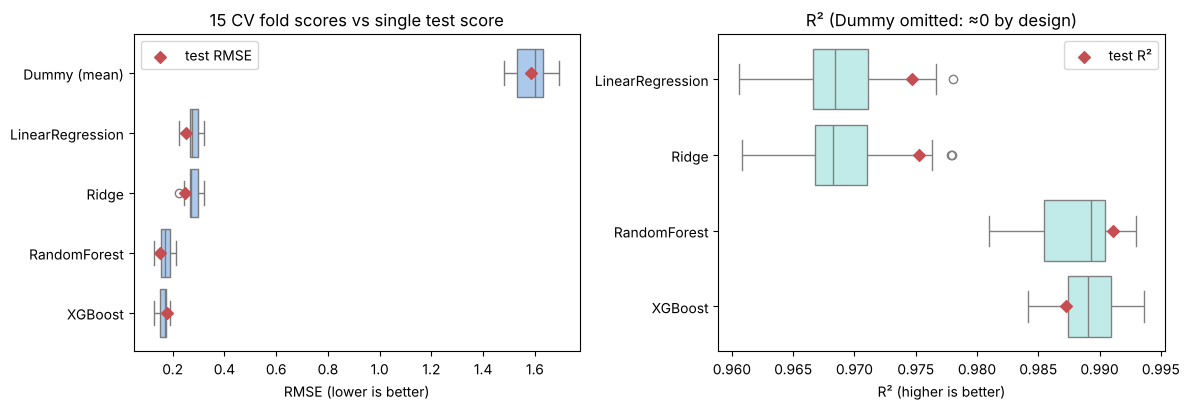

,model,cv_RMSE_mean,test_RMSE,test_minus_cv_RMSE
0,Dummy (mean),1.588,1.584,-0.004
1,LinearRegression,0.278,0.252,-0.026
2,Ridge,0.276,0.249,-0.028
3,RandomForest,0.170,0.149,-0.021
4,XGBoost,0.164,0.178,0.015


In [7]:
order = comp.sort_values("cv_RMSE_mean", ascending=False).model.tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=cv_df, y="model", x="valid_RMSE", order=order, ax=axes[0], color="#A1C9F4")
axes[0].scatter(comp.set_index("model").loc[order, "test_RMSE"], range(len(order)), color="#C44E52", zorder=5, marker="D", label="test RMSE")
axes[0].set_xlabel("RMSE (lower is better)"); axes[0].set_ylabel(""); axes[0].legend(); axes[0].set_title("15 CV fold scores vs single test score")
nd = [m for m in order if not m.startswith("Dummy")]
sns.boxplot(data=cv_df[cv_df.model.isin(nd)], y="model", x="valid_R2", order=nd, ax=axes[1], color="#B9F2F0")
axes[1].scatter(comp.set_index("model").loc[nd, "test_R2"], range(len(nd)), color="#C44E52", zorder=5, marker="D", label="test R²")
axes[1].set_xlabel("R² (higher is better)"); axes[1].set_ylabel(""); axes[1].legend(); axes[1].set_title("R² (Dummy omitted: ≈0 by design)")
plt.tight_layout(); plt.savefig(FIG / "fig02_cv_vs_test.png", dpi=150); plt.show()
display(comp[["model", "cv_RMSE_mean", "test_RMSE", "test_minus_cv_RMSE"]].round(3))

### 7.2 Overfitting: training error vs held-out error
**Overfitting** means the model memorises its training rows: very low training error and much higher error on new rows.
The gap below is (validation RMSE − training RMSE), averaged over the CV folds.
**Learning curves** show how error changes as the model gets more training data. If the two curves are still far apart at the full data size, more data would probably help.

,model,cv_train_RMSE_mean,cv_RMSE_mean,overfit_gap_RMSE (cv_valid - cv_train)
0,Dummy (mean),1.586,1.588,0.002
1,LinearRegression,0.248,0.278,0.030
2,Ridge,0.249,0.276,0.027
3,RandomForest,0.072,0.170,0.098
4,XGBoost,0.053,0.164,0.111


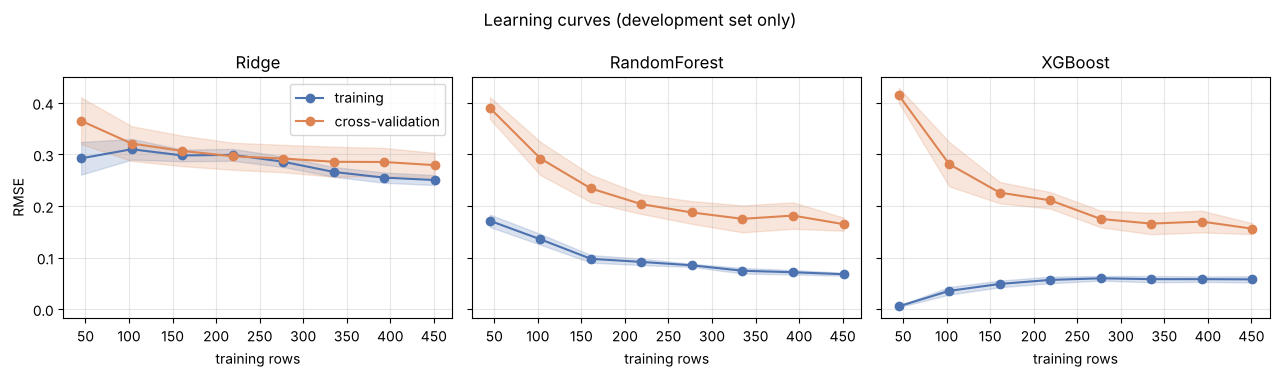

In [8]:
display(comp[["model", "cv_train_RMSE_mean", "cv_RMSE_mean", "overfit_gap_RMSE (cv_valid - cv_train)"]].round(3))

lc_models = [m for m in ["Ridge", "RandomForest", boost_name] if m in final_models]
fig, axes = plt.subplots(1, len(lc_models), figsize=(4.3 * len(lc_models), 3.8), sharey=True)
for ax, name in zip(np.atleast_1d(axes), lc_models):
    sizes, tr_s, va_s = learning_curve(clone(final_models[name]), X_dev, y_dev, cv=inner_cv,
                                       train_sizes=np.linspace(0.1, 1.0, 8), scoring="neg_root_mean_squared_error", n_jobs=-1)
    for s, lab, col in [(-tr_s, "training", "#4C72B0"), (-va_s, "cross-validation", "#DD8452")]:
        ax.plot(sizes, s.mean(1), "o-", label=lab, color=col)
        ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2, color=col)
    ax.set_title(name); ax.set_xlabel("training rows"); ax.grid(alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("RMSE"); np.atleast_1d(axes)[0].legend()
plt.suptitle("Learning curves (development set only)"); plt.tight_layout()
plt.savefig(FIG / "fig03_learning_curves.png", dpi=150); plt.show()

### 7.3 Predicted vs actual scores (test set)
Points on the dashed diagonal are perfect predictions. The true scores are whole numbers, so small horizontal jitter is added to make overlapping points visible.

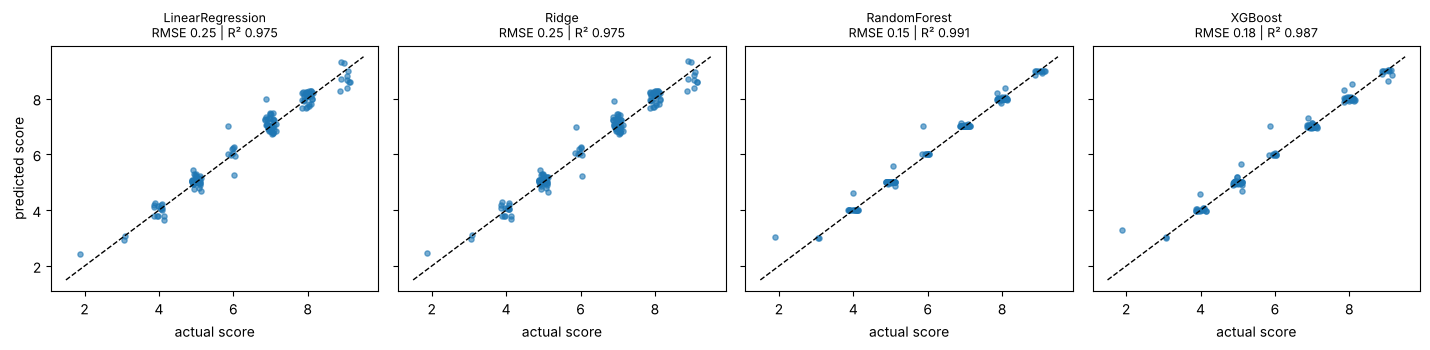

In [9]:
names = [m for m in MODELS if not m.startswith("Dummy")]
fig, axes = plt.subplots(1, len(names), figsize=(3.6 * len(names), 3.6), sharex=True, sharey=True)
jit = np.random.default_rng(SEED).uniform(-0.15, 0.15, len(y_test))
for ax, name in zip(axes, names):
    ax.scatter(y_test + jit, test_preds[name], s=14, alpha=0.6)
    ax.plot([1.5, 9.5], [1.5, 9.5], "k--", lw=1)
    r = comp.set_index("model").loc[name]
    ax.set_title(f"{name}\nRMSE {r.test_RMSE:.2f} | R² {r.test_R2:.3f}", fontsize=9)
    ax.set_xlabel("actual score")
axes[0].set_ylabel("predicted score")
plt.tight_layout(); plt.savefig(FIG / "fig04_pred_vs_actual_test.png", dpi=150); plt.show()

### 7.4 Residual analysis (best model by CV)
A **residual** is (actual − predicted). For a reliable model, residuals should centre on 0, show no pattern against the prediction, and not be systematically off for particular score levels.

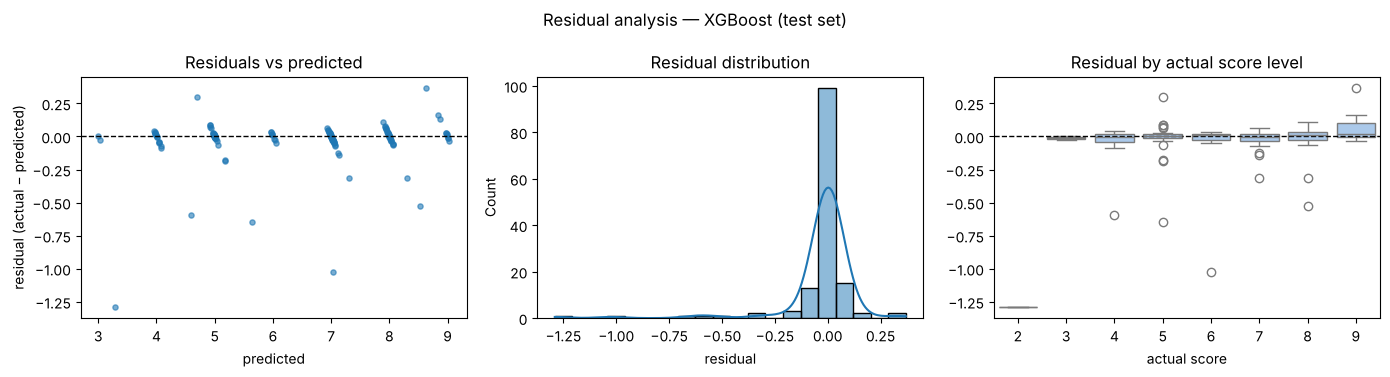

,n,MAE,mean_residual
actual,,,
2,1,1.291,-1.291
3,2,0.015,-0.015
4,15,0.070,-0.048
5,35,0.056,-0.011
6,9,0.138,-0.111
7,41,0.039,-0.018
8,28,0.064,-0.018
9,10,0.080,0.069


Mean residual -0.028, largest absolute error 1.291


In [10]:
res_test = y_test.to_numpy() - test_preds[best_cv]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].scatter(test_preds[best_cv], res_test, s=14, alpha=0.6); axes[0].axhline(0, color="k", ls="--", lw=1)
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("residual (actual − predicted)"); axes[0].set_title("Residuals vs predicted")
sns.histplot(res_test, bins=20, kde=True, ax=axes[1]); axes[1].set_title("Residual distribution"); axes[1].set_xlabel("residual")
sns.boxplot(x=y_test.to_numpy(), y=res_test, ax=axes[2], color="#A1C9F4"); axes[2].axhline(0, color="k", ls="--", lw=1)
axes[2].set_xlabel("actual score"); axes[2].set_title("Residual by actual score level")
plt.suptitle(f"Residual analysis — {best_cv} (test set)"); plt.tight_layout()
plt.savefig(FIG / "fig05_residuals_best_model.png", dpi=150); plt.show()

by_level = (pd.DataFrame({"actual": y_test.to_numpy(), "abs_err": np.abs(res_test), "resid": res_test})
            .groupby("actual").agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), mean_residual=("resid", "mean")).round(3))
by_level.to_csv(RESULTS / "residuals_by_score_level.csv")
display(by_level)
print(f"Mean residual {res_test.mean():.3f}, largest absolute error {np.abs(res_test).max():.3f}")

### 7.5 How much does one split matter?
A single test score depends on which students were drawn into the test set. Here we re-split the **development set only** (the real test set is not touched) 50 times, 80/20, and refit each model with its chosen settings.
The spread of the results shows how much a "one split" number from any notebook can move by chance.

RMSE                          R2                     
                   mean    std    min    max   mean    std    min    max
model                                                                   
LinearRegression  0.278  0.028  0.217  0.335  0.969  0.006  0.955  0.982
RandomForest      0.184  0.030  0.130  0.268  0.986  0.005  0.974  0.994
Ridge             0.276  0.028  0.216  0.328  0.970  0.006  0.958  0.983
XGBoost           0.175  0.031  0.123  0.249  0.988  0.004  0.976  0.994

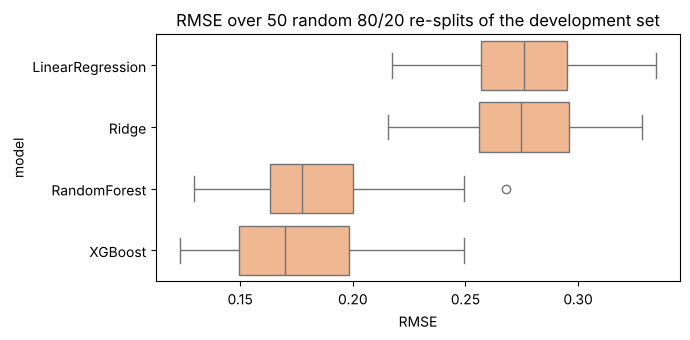

In [11]:
sens = []
for s in range(50):
    a_X, b_X, a_y, b_y = train_test_split(X_dev, y_dev, test_size=0.2, random_state=s)
    for name in ["LinearRegression", "Ridge", "RandomForest", boost_name]:
        p = clone(final_models[name]).fit(a_X, a_y).predict(b_X)
        m = metrics(b_y, p); m.update(model=name, split_seed=s); sens.append(m)
sens = pd.DataFrame(sens)
sens.round(5).to_csv(RESULTS / "split_sensitivity.csv", index=False)
summary = sens.groupby("model")[["RMSE", "R2"]].agg(["mean", "std", "min", "max"]).round(3)
display(summary)
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(data=sens, x="RMSE", y="model", ax=ax, color="#FFB482")
ax.set_title("RMSE over 50 random 80/20 re-splits of the development set"); plt.tight_layout()
plt.savefig(FIG / "fig06_split_sensitivity.png", dpi=150); plt.show()

## 8. Are the high scores trustworthy? Leakage and suspicious-result checks

The baselines reach very high R². Before believing it, we test for the usual causes of inflated results:

| Check | What it would reveal |
|---|---|
| (a) Duplicates and ID leakage | Covered in Section 2 |
| (b) **Permutation (shuffled-target) test** | If the pipeline still scores well after the target is shuffled at random, information is leaking. |
| (c) **Single-feature models** | Whether one feature almost *is* the target, i.e. is target-derived |
| (d) **Country encoding** | The original unsmoothed target-mean encoding vs safe alternatives |
| (e) **Feature-set sensitivity** | How much performance depends on features that may be *consequences* of addiction rather than predictors |
| (f) **Metric calculation** | sklearn metrics recomputed by hand |

XGBoost: CV R² with real target = 0.990
CV R² with shuffled target: mean -0.237, max -0.132  (p = 0.0099)


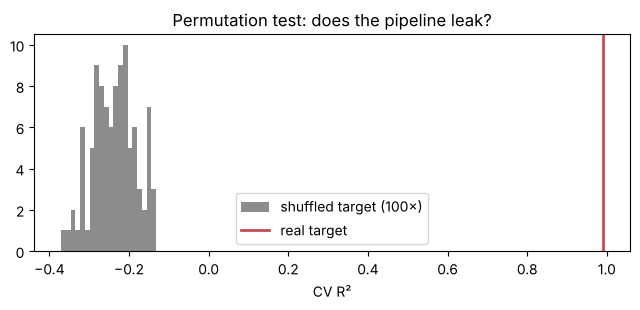

In [12]:
# (b) Permutation test on the development set (fixed, already-chosen settings)
perm_model = clone(final_models[best_cv])
score, perm_scores, pval = permutation_test_score(perm_model, X_dev, y_dev, cv=inner_cv, scoring="r2",
                                                  n_permutations=100, random_state=SEED, n_jobs=-1)
print(f"{best_cv}: CV R² with real target = {score:.3f}")
print(f"CV R² with shuffled target: mean {perm_scores.mean():.3f}, max {perm_scores.max():.3f}  (p = {pval:.4f})")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(perm_scores, bins=20, color="#8C8C8C", label="shuffled target (100×)")
ax.axvline(score, color="#C44E52", lw=2, label="real target")
ax.set_xlabel("CV R²"); ax.legend(); ax.set_title("Permutation test: does the pipeline leak?")
plt.tight_layout(); plt.savefig(FIG / "fig07_permutation_test.png", dpi=150); plt.show()

In [13]:
# (c) How much does each single feature predict on its own? (Ridge for numeric, one-hot + Ridge for categorical)
single = []
for col in FEATURES:
    num = col in NUM
    pre1 = ColumnTransformer([("x", StandardScaler() if num else OneHotEncoder(min_frequency=10 if col == "Country" else None,
                               handle_unknown="infrequent_if_exist" if col == "Country" else "ignore", sparse_output=False), [col])])
    r = cross_validate(Pipeline([("pre", pre1), ("m", Ridge(alpha=1.0))]), X_dev, y_dev, cv=inner_cv, scoring="r2")
    single.append({"feature": col, "type": "numeric" if num else "categorical",
                   "cv_R2_alone": r["test_score"].mean(),
                   "pearson_r_with_target": round(X_dev[col].corr(y_dev), 3) if num else np.nan})
single = pd.DataFrame(single).sort_values("cv_R2_alone", ascending=False)
single.round(4).to_csv(RESULTS / "single_feature_r2.csv", index=False)
display(single.round(3))

,feature,type,cv_R2_alone,pearson_r_with_target
8,Mental_Health_Score,numeric,0.892,-0.945
10,Conflicts_Over_Social_Media,numeric,0.863,0.930
6,Affects_Academic_Performance,categorical,0.743,NaN
4,Avg_Daily_Usage_Hours,numeric,0.690,0.833
7,Sleep_Hours_Per_Night,numeric,0.579,-0.764
3,Country,categorical,0.464,NaN
5,Most_Used_Platform,categorical,0.325,NaN
2,Academic_Level,categorical,0.026,NaN
0,Age,numeric,0.017,-0.154
1,Gender,categorical,-0.003,NaN


In [14]:
# (d) Country encoding comparison — same model, same folds, only the Country treatment changes
cty_rows = []
for strat in ["drop", "rare_onehot", "target_cv", "naive_target"]:
    for name, model in [("Ridge", Ridge(alpha=1.0)),
                        ("RandomForest", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))]:
        r = cross_validate(pipe(model, country=strat), X_dev, y_dev, cv=outer_cv,
                           scoring="neg_root_mean_squared_error", return_train_score=True)
        cty_rows.append({"country_strategy": strat, "model": name,
                         "train_RMSE": -r["train_score"].mean(), "cv_RMSE": -r["test_score"].mean(),
                         "cv_RMSE_std": r["test_score"].std()})
cty = pd.DataFrame(cty_rows); cty["overfit_gap"] = cty.cv_RMSE - cty.train_RMSE
cty.round(4).to_csv(RESULTS / "country_encoding_comparison.csv", index=False)
display(cty.round(3))

,country_strategy,model,train_RMSE,cv_RMSE,cv_RMSE_std,overfit_gap
0,drop,Ridge,0.281,0.292,0.023,0.011
1,drop,RandomForest,0.084,0.218,0.025,0.134
2,rare_onehot,Ridge,0.249,0.276,0.024,0.027
3,rare_onehot,RandomForest,0.067,0.171,0.025,0.104
4,target_cv,Ridge,0.266,0.275,0.022,0.008
5,target_cv,RandomForest,0.101,0.189,0.030,0.088
6,naive_target,Ridge,0.258,0.285,0.023,0.027
7,naive_target,RandomForest,0.070,0.211,0.050,0.142


**(e) Feature-set sensitivity.** `Mental_Health_Score`, `Conflicts_Over_Social_Media` and `Affects_Academic_Performance` could plausibly be *consequences* of heavy use, or be measured with the same survey questions as the score.
If performance collapses without them, the "prediction" mostly re-states closely related survey answers.
That is a limit on how the model can be interpreted. It is not a bug.

model,RandomForest,Ridge,XGBoost
feature_set,,,
A: all features,0.988,0.969,0.989
B: without Country,0.981,0.966,0.984
C: without outcome-like features,0.933,0.854,0.943
D: only usage hours + sleep + demographics,0.927,0.831,0.934
E: only Mental_Health_Score + Conflicts,0.953,0.929,0.949


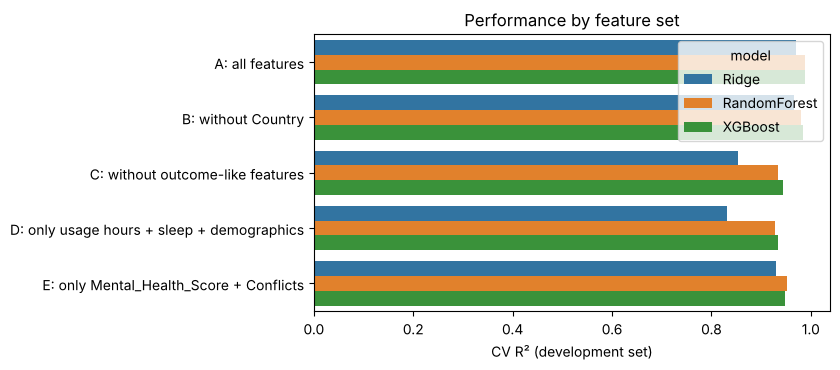

In [15]:
OUTCOME_LIKE = ["Mental_Health_Score", "Conflicts_Over_Social_Media", "Affects_Academic_Performance"]
sets = {"A: all features": (),
        "B: without Country": ("Country",),
        "C: without outcome-like features": tuple(OUTCOME_LIKE),
        "D: only usage hours + sleep + demographics": tuple(OUTCOME_LIKE + ["Most_Used_Platform", "Relationship_Status"]),
        "E: only Mental_Health_Score + Conflicts": tuple(c for c in FEATURES if c not in ["Mental_Health_Score", "Conflicts_Over_Social_Media"])}
fs_rows = []
for set_name, drop in sets.items():
    for name in ["Ridge", "RandomForest", boost_name]:
        best_model = final_models[name].named_steps["model"]
        r = cross_validate(Pipeline([("pre", make_preprocessor(drop=drop)), ("model", clone(best_model))]),
                           X_dev, y_dev, cv=outer_cv, scoring={"RMSE": "neg_root_mean_squared_error", "R2": "r2"}, n_jobs=-1)
        fs_rows.append({"feature_set": set_name, "dropped": ", ".join(drop) if drop else "-", "model": name,
                        "cv_RMSE": -r["test_RMSE"].mean(), "cv_R2": r["test_R2"].mean(), "cv_R2_std": r["test_R2"].std()})
fs = pd.DataFrame(fs_rows)
fs.round(4).to_csv(RESULTS / "feature_set_sensitivity.csv", index=False)
display(fs.pivot(index="feature_set", columns="model", values="cv_R2").round(3))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sns.barplot(data=fs, y="feature_set", x="cv_R2", hue="model", ax=ax)
ax.set_xlabel("CV R² (development set)"); ax.set_ylabel(""); ax.set_title("Performance by feature set")
plt.tight_layout(); plt.savefig(FIG / "fig08_feature_set_sensitivity.png", dpi=150); plt.show()

In [16]:
# (f) Metric sanity check: recompute by hand and compare with sklearn
yt, yp = y_test.to_numpy(), test_preds[best_cv]
manual = {"MAE": np.mean(np.abs(yt - yp)), "MSE": np.mean((yt - yp) ** 2)}
manual["RMSE"] = np.sqrt(manual["MSE"])
manual["R2"] = 1 - np.sum((yt - yp) ** 2) / np.sum((yt - yt.mean()) ** 2)
sk = metrics(yt, yp)
assert all(np.isclose(manual[k], sk[k]) for k in manual), "Metric mismatch!"
print("Hand-computed metrics match sklearn:", {k: round(v, 4) for k, v in manual.items()})

Hand-computed metrics match sklearn: {'MAE': np.float64(0.0694), 'MSE': np.float64(0.0318), 'RMSE': np.float64(0.1784), 'R2': np.float64(0.9873)}


## 9. Audit of previously recorded results (StablePFN notebook)

This section separates what we can **verify** from what we cannot. **StablePFN is not retrained here.**
We check (i) whether its recorded numbers are internally consistent with the test set they claim to use, and (ii) how simple models perform with the **original** preprocessing and split.

In [17]:
var_test = np.mean((y_test - y_test.mean()) ** 2)          # the denominator sklearn's R² uses
rec_mse, rec_mae, rec_r2 = 0.8935, 0.7146, 0.6429           # RECORDED in the StablePFN notebook output
implied_r2 = 1 - rec_mse / var_test
n_pos7, n_pos6 = int((y_test >= 7).sum()), int((y_test >= 6).sum())
dummy_mse = comp.set_index("model").loc["Dummy (mean)", "test_MSE"]

audit = pd.DataFrame([
    {"item": "StablePFN test MSE / MAE / R²", "source": "StablePFN notebook output",
     "recorded_value": f"{rec_mse} / {rec_mae} / {rec_r2}",
     "check": f"Implied R² from recorded MSE on this test set = {implied_r2:.4f}",
     "status": "CONSISTENT with the 141-row test set (model itself NOT re-run)" if abs(implied_r2 - rec_r2) < 0.005 else "INCONSISTENT"},
    {"item": "Binary classification confusion matrix (TN 62, FP 0, FN 79, TP 0)", "source": "StablePFN notebook output",
     "recorded_value": "threshold labelled '>= 6.0' in text",
     "check": f"Test rows with score >= 7: {n_pos7}; with score >= 6: {n_pos6}",
     "status": ("VERIFIED: positives = 79 matches threshold 7.0, not 6.0 -> label in notebook is wrong" if n_pos7 == 79 else "UNRESOLVED")},
    {"item": "Binary precision/recall/F1 = 0", "source": "StablePFN notebook output", "recorded_value": "0 / 0 / 0",
     "check": "Follows from TP = 0: the model never predicted >= 7", "status": "EXPLAINED (degenerate classifier)"},
    {"item": "Hard masking (gate threshold 0.5) test MSE", "source": "StablePFN notebook output", "recorded_value": "22.9344",
     "check": f"Mean-only Dummy test MSE = {dummy_mse:.4f}", "status": "PLAUSIBLE: all gates < 0.05, so every input is zeroed; worse than predicting the mean"},
    {"item": "Run-2 retrain test metrics; iLTM, TabSRA, baseline, multiclass, NLP results", "source": "not readable / not provided",
     "recorded_value": "-", "check": "-", "status": "UNVERIFIED (cells beyond the readable part of the export)"},
])
display(audit)
print(f"Test-set variance (ddof=0) = {var_test:.4f}; implied StablePFN R² = {implied_r2:.4f} vs recorded {rec_r2}")

,item,source,recorded_value,check,status
0,StablePFN test MSE / MAE / R²,StablePFN notebook output,0.8935 / 0.7146 / 0.6429,Implied R² from recorded MSE on this test set ...,CONSISTENT with the 141-row test set (model it...
1,"Binary classification confusion matrix (TN 62,...",StablePFN notebook output,threshold labelled '>= 6.0' in text,Test rows with score >= 7: 79; with score >= 6...,VERIFIED: positives = 79 matches threshold 7.0...
2,Binary precision/recall/F1 = 0,StablePFN notebook output,0 / 0 / 0,Follows from TP = 0: the model never predicted...,EXPLAINED (degenerate classifier)
3,Hard masking (gate threshold 0.5) test MSE,StablePFN notebook output,22.9344,Mean-only Dummy test MSE = 2.5095,"PLAUSIBLE: all gates < 0.05, so every input is..."
4,"Run-2 retrain test metrics; iLTM, TabSRA, base...",not readable / not provided,-,-,UNVERIFIED (cells beyond the readable part of ...


Test-set variance (ddof=0) = 2.5023; implied StablePFN R² = 0.6429 vs recorded 0.6429


In [18]:
# Faithful re-creation of the ORIGINAL preprocessing (unscaled, naive Country target-mean, get_dummies),
# trained on the ORIGINAL 493-row train split, evaluated on original val (71) and test (141).
def original_preprocess(Xtr, ytr, others):
    def base(d):
        d = d.copy()
        d["Gender"] = (d["Gender"] == "Male").astype(int)
        d["Affects_Academic_Performance"] = (d["Affects_Academic_Performance"] == "Yes").astype(int)
        d["Academic_Level"] = d["Academic_Level"].map({"High School": 0, "Undergraduate": 1, "Graduate": 2})
        d["Relationship_Status"] = d["Relationship_Status"].map({"Single": 0, "In Relationship": 1, "Complicated": 2})
        return d
    means, gm = ytr.groupby(Xtr["Country"]).mean(), ytr.mean()
    out = []
    for d in [Xtr] + others:
        b = base(d); b["Country"] = b["Country"].map(means).fillna(gm)
        out.append(pd.get_dummies(b, columns=["Most_Used_Platform"], prefix="Platform", dtype=int))
    cols = out[0].columns
    return [o.reindex(columns=cols, fill_value=0) for o in out]

Xtr_o, Xva_o, Xte_o = original_preprocess(X_tr_orig, y_tr_orig, [X_val_orig, X_test])
print("Original-style feature count:", Xtr_o.shape[1], "(original notebook reported 22)")
repro = []
orig_models = {"LinearRegression": LinearRegression(),
               "RandomForest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)}
if HAS_XGB:
    orig_models["XGBoost"] = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEED, n_jobs=1, verbosity=0)
for name, m in orig_models.items():
    m.fit(Xtr_o, y_tr_orig)
    for split, Xs, ys in [("train (493)", Xtr_o, y_tr_orig), ("val (71)", Xva_o, y_val_orig), ("test (141)", Xte_o, y_test)]:
        r = metrics(ys, m.predict(Xs)); r.update(model=name, split=split, pipeline="original preprocessing (re-created)", status="VERIFIED")
        repro.append(r)
repro.append({"model": "StablePFN (run 1)", "split": "test (141)", "pipeline": "original notebook", "MAE": rec_mae,
              "MSE": rec_mse, "RMSE": np.sqrt(rec_mse), "R2": rec_r2, "status": "RECORDED (unverified, not re-run)"})
repro = pd.DataFrame(repro)[["pipeline", "model", "split", "MAE", "MSE", "RMSE", "R2", "status"]]
repro.round(4).to_csv(RESULTS / "original_pipeline_reproduction.csv", index=False)
display(repro.round(3))

audit.to_csv(RESULTS / "previous_results_audit.csv", index=False)
print("Saved results/previous_results_audit.csv and results/original_pipeline_reproduction.csv")

Original-style feature count: 22 (original notebook reported 22)


,pipeline,model,split,MAE,MSE,RMSE,R2,status
0,original preprocessing (re-created),LinearRegression,train (493),0.188,0.061,0.248,0.976,VERIFIED
1,original preprocessing (re-created),LinearRegression,val (71),0.244,0.115,0.339,0.954,VERIFIED
2,original preprocessing (re-created),LinearRegression,test (141),0.210,0.072,0.268,0.971,VERIFIED
3,original preprocessing (re-created),RandomForest,train (493),0.020,0.005,0.070,0.998,VERIFIED
4,original preprocessing (re-created),RandomForest,val (71),0.078,0.072,0.268,0.971,VERIFIED
5,original preprocessing (re-created),RandomForest,test (141),0.054,0.028,0.166,0.989,VERIFIED
6,original preprocessing (re-created),XGBoost,train (493),0.065,0.012,0.111,0.995,VERIFIED
7,original preprocessing (re-created),XGBoost,val (71),0.116,0.054,0.233,0.978,VERIFIED
8,original preprocessing (re-created),XGBoost,test (141),0.110,0.041,0.201,0.984,VERIFIED
9,original notebook,StablePFN (run 1),test (141),0.715,0.894,0.945,0.643,"RECORDED (unverified, not re-run)"


Saved results/previous_results_audit.csv and results/original_pipeline_reproduction.csv


## 10. Feature importance (descriptive, NOT causal)

**Permutation importance** shuffles one *original* column in the test set and measures how much RMSE gets worse.
Shuffling `Country` or `Most_Used_Platform` shuffles the whole category at once, so the one-hot columns are scored as a group.
A large value means *this model relies on this column for its predictions*. It does **not** mean that changing this column in a real student would change their addiction score.

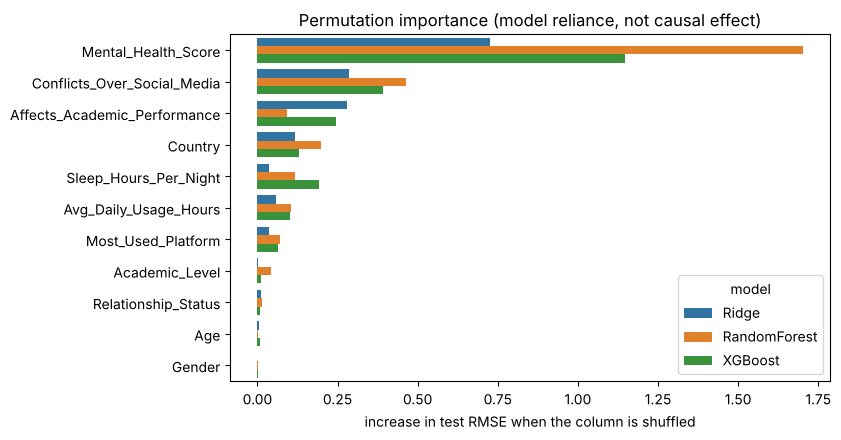

Top Ridge coefficients (numeric features are standardised, so their sizes are comparable):


,coefficient
bin__Affects_Academic_Performance_Yes,0.677
num__Mental_Health_Score,-0.672
nom__Most_Used_Platform_LINE,-0.541
ctry__Country_South Korea,-0.492
ctry__Country_Maldives,0.479
nom__Most_Used_Platform_YouTube,0.361
ctry__Country_USA,0.334
num__Conflicts_Over_Social_Media,0.326
ctry__Country_Japan,-0.304
nom__Most_Used_Platform_Snapchat,0.286


In [19]:
imp_rows = []
for name in ["Ridge", "RandomForest", boost_name]:
    pi = permutation_importance(final_models[name], X_test, y_test, scoring="neg_root_mean_squared_error",
                                n_repeats=30, random_state=SEED, n_jobs=-1)
    for f, mu, sd in zip(X_test.columns, pi.importances_mean, pi.importances_std):
        imp_rows.append({"model": name, "feature": f, "RMSE_increase_mean": mu, "RMSE_increase_std": sd})
imp = pd.DataFrame(imp_rows)
imp.round(5).to_csv(RESULTS / "permutation_importance_test.csv", index=False)
order_f = imp.groupby("feature").RMSE_increase_mean.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.barplot(data=imp, y="feature", x="RMSE_increase_mean", hue="model", order=order_f, ax=ax)
ax.set_xlabel("increase in test RMSE when the column is shuffled"); ax.set_ylabel("")
ax.set_title("Permutation importance (model reliance, not causal effect)")
plt.tight_layout(); plt.savefig(FIG / "fig09_permutation_importance.png", dpi=150); plt.show()

ridge = final_models["Ridge"]
coefs = pd.Series(ridge.named_steps["model"].coef_, index=ridge.named_steps["pre"].get_feature_names_out())
coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
coefs.round(4).rename("ridge_coefficient").to_csv(RESULTS / "ridge_coefficients.csv")
print("Top Ridge coefficients (numeric features are standardised, so their sizes are comparable):")
display(coefs.head(10).round(3).to_frame("coefficient"))

## 11. Summary of outputs

All numbers in the files below come from running this notebook (**VERIFIED**). The only exception is the rows marked **RECORDED** in the two audit tables.

In [20]:
for p in sorted(RESULTS.rglob("*")):
    if p.is_file():
        print(p.relative_to(ROOT).as_posix())
print("\nBest model by CV:", best_cv)
display(comp[["model", "cv_RMSE_mean", "cv_R2_mean", "test_RMSE", "test_R2", "test_R2_CI95_low", "test_R2_CI95_high"]].round(3))

results/country_encoding_comparison.csv
results/cross_validation_results.csv
results/environment.json
results/feature_set_sensitivity.csv
results/figures/fig01_split_target_distribution.png
results/figures/fig02_cv_vs_test.png
results/figures/fig03_learning_curves.png
results/figures/fig04_pred_vs_actual_test.png
results/figures/fig05_residuals_best_model.png
results/figures/fig06_split_sensitivity.png
results/figures/fig07_permutation_test.png
results/figures/fig08_feature_set_sensitivity.png
results/figures/fig09_permutation_importance.png
results/model_comparison.csv
results/original_pipeline_reproduction.csv
results/permutation_importance_test.csv
results/previous_results_audit.csv
results/residuals_by_score_level.csv
results/ridge_coefficients.csv
results/single_feature_r2.csv
results/split_sensitivity.csv
results/test_indices.csv

Best model by CV: XGBoost


,model,cv_RMSE_mean,cv_R2_mean,test_RMSE,test_R2,test_R2_CI95_low,test_R2_CI95_high
0,Dummy (mean),1.588,-0.009,1.584,-0.003,-0.047,-0.000
1,LinearRegression,0.278,0.969,0.252,0.975,0.962,0.983
2,Ridge,0.276,0.969,0.249,0.975,0.963,0.983
3,RandomForest,0.170,0.988,0.149,0.991,0.982,0.998
4,XGBoost,0.164,0.989,0.178,0.987,0.975,0.997
